https://kaggle.com/datasets/birdy654/eeg-brainwave-dataset-feeling-emotions

1. How many records belong to each emotion? (one category column)
2. What is the distribution of the mean_1_a feature? (one numeric column)
3. Which emotion has the highest average mean_1_a? (numeric feature compared by category)
4. Does stddev_0_a vary across the three emotions? (numeric feature compared by category)
5. How are the values of entropy0_a distributed? (one numeric feature)
6. Is there a relationship between mean_1_a and stddev_0_a? (two numeric columns)
7. Which of the selected EEG features are correlated? (multiple numeric columns)
8. Which emotion has the highest average fft_0_a? (numeric feature compared by category)

# EDA Assignment: EEG Emotion Dataset

Dataset: emotions.csv

Goal: Explore EEG feature values and compare the three emotion labels: POSITIVE, NEGATIVE and NEUTRAL.

## Plane:
1. Load the dataset.
2. Display the first five rows.
3. Check rows and columns.
4. Check missing values.
5. Clean the data if needed.
6. Calculate basic statistics.
7. Analyze brainwave frequency bands.
8. Compare different emotions (Happy vs Sad vs Relex) etc.
9. Create simple and modern graphs.

4. Brainwave Types
We will analyze five main brainwave types.

| Brainwave | Frequency | Associated Activity |
| :--- | :--- | :--- |
| Delta | 0.5 - 4 Hz | Deep Sleep |
| Theta | 4 - 8 Hz | Relaxation |
| Alpha | 8 - 13 Hz | Calm and Relaxed State |
| Beta | 13 - 30 Hz | Active Thinking |
| Gamma | 30+ Hz | High Focus and Concentration |

# 1. Upload the dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Download `/content/emotions.csv.zip` from Kaggle and upload it into Colab (folder icon on the left, then the upload button). Then read it.

In [ ]:
df = pd.read_csv("/content/emotions.csv.zip")
df.shape

(2132, 2549)

The dataset has 2132 rows and 2549 columns.

## 2. Display the first five rows

In [ ]:
df.head()

,# mean_0_a,mean_1_a,mean_2_a,mean_3_a,mean_4_a,mean_d_0_a,mean_d_1_a,mean_d_2_a,mean_d_3_a,mean_d_4_a,...,fft_741_b,fft_742_b,fft_743_b,fft_744_b,fft_745_b,fft_746_b,fft_747_b,fft_748_b,fft_749_b,label
0,4.62,30.3,-356.0,15.6,26.3,1.070,0.411,-15.70,2.06,3.15,...,23.5,20.3,20.3,23.5,-215.0,280.00,-162.00,-162.00,280.00,NEGATIVE
1,28.80,33.1,32.0,25.8,22.8,6.550,1.680,2.88,3.83,-4.82,...,-23.3,-21.8,-21.8,-23.3,182.0,2.57,-31.60,-31.60,2.57,NEUTRAL
2,8.90,29.4,-416.0,16.7,23.7,79.900,3.360,90.20,89.90,2.03,...,462.0,-233.0,-233.0,462.0,-267.0,281.00,-148.00,-148.00,281.00,POSITIVE
3,14.90,31.6,-143.0,19.8,24.3,-0.584,-0.284,8.82,2.30,-1.97,...,299.0,-243.0,-243.0,299.0,132.0,-12.40,9.53,9.53,-12.40,POSITIVE
4,28.30,31.3,45.2,27.3,24.5,34.800,-5.790,3.06,41.40,5.52,...,12.0,38.1,38.1,12.0,119.0,-17.60,23.90,23.90,-17.60,NEUTRAL


The first five rows show the starting values of the dataset. Columns like mean_0_a, mean_1_a are brainwave (EEG) features, and the last column 'label' shows the emotion.

## 3. Check Rows and Columns

In [ ]:
df.columns

Index(['# mean_0_a', 'mean_1_a', 'mean_2_a', 'mean_3_a', 'mean_4_a',
       'mean_d_0_a', 'mean_d_1_a', 'mean_d_2_a', 'mean_d_3_a', 'mean_d_4_a',
       ...
       'fft_741_b', 'fft_742_b', 'fft_743_b', 'fft_744_b', 'fft_745_b',
       'fft_746_b', 'fft_747_b', 'fft_748_b', 'fft_749_b', 'label'],
      dtype='object', length=2549)

The dataset has 2549 columns. The columns include mean, fft features and the last column 'label' which is the emotion.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2132 entries, 0 to 2131
Columns: 2549 entries, # mean_0_a to label
dtypes: float64(2548), object(1)
memory usage: 41.5+ MB


Info shows the dataset has 2132 rows and 2549 columns. 2548 columns are numbers (float) and 1 column 'label' is text (object). Memory usage is 41.5 MB.

In [ ]:
df.dtypes

,0
# mean_0_a,float64
mean_1_a,float64
mean_2_a,float64
mean_3_a,float64
mean_4_a,float64
...,...
fft_746_b,float64
fft_747_b,float64
fft_748_b,float64
fft_749_b,float64


This shows the data type of each column. Brainwave columns are float numbers and label column is object (text).

## 4. Check missing value

In [ ]:
df.isnull().sum()

,0
# mean_0_a,0
mean_1_a,0
mean_2_a,0
mean_3_a,0
mean_4_a,0
...,...
fft_746_b,0
fft_747_b,0
fft_748_b,0
fft_749_b,0


There are no missing values in the dataset. All columns show 0, so the data is complete and clean.

## 5. Clean the data if needed

In [ ]:
# just check duplicates
df.duplicated().sum()

np.int64(0)

Data is already clean. There are no missing values, so no cleaning was needed.

## 6. Calculate basic statistics.

In [ ]:
df.describe()

,# mean_0_a,mean_1_a,mean_2_a,mean_3_a,mean_4_a,mean_d_0_a,mean_d_1_a,mean_d_2_a,mean_d_3_a,mean_d_4_a,...,fft_740_b,fft_741_b,fft_742_b,fft_743_b,fft_744_b,fft_745_b,fft_746_b,fft_747_b,fft_748_b,fft_749_b
count,2132.000000,2132.000000,2132.000000,2132.000000,2132.000000,2132.000000,2132.000000,2132.000000,2132.000000,2132.000000,...,2132.000000,2132.000000,2132.000000,2132.000000,2132.000000,2132.000000,2132.000000,2132.000000,2132.000000,2132.000000
mean,15.256914,27.012462,-104.975629,13.605898,24.150483,0.025378,0.052282,0.301655,0.036793,0.083567,...,-22.938971,104.946111,-51.973647,-51.973647,104.946111,-6.934144,95.104886,-49.061255,-49.061255,95.104886
std,15.284621,9.265141,206.271960,16.874676,14.187340,17.981796,8.509174,68.098894,17.010031,18.935378,...,298.034311,212.532721,112.160233,112.160233,212.532721,281.040552,203.194976,106.486317,106.486317,203.194976
min,-61.300000,-114.000000,-970.000000,-137.000000,-217.000000,-218.000000,-255.000000,-1360.000000,-203.000000,-553.000000,...,-1180.000000,-921.000000,-504.000000,-504.000000,-921.000000,-1160.000000,-1010.000000,-521.000000,-521.000000,-1010.000000
25%,6.577500,26.075000,-195.000000,4.857500,23.600000,-3.105000,-1.340000,-4.002500,-2.905000,-2.622500,...,-106.500000,-8.365000,-92.900000,-92.900000,-8.365000,-102.500000,-8.837500,-87.150000,-87.150000,-8.837500
50%,14.100000,30.000000,14.950000,15.400000,25.200000,-0.044600,0.132000,0.957500,-0.099750,0.146500,...,83.850000,12.150000,-21.800000,-21.800000,12.150000,89.700000,13.400000,-24.100000,-24.100000,13.400000
75%,27.700000,31.400000,29.600000,26.500000,26.800000,2.920000,1.540000,6.735000,2.535000,2.870000,...,154.000000,177.000000,12.025000,12.025000,177.000000,153.000000,149.250000,10.925000,10.925000,149.250000
max,304.000000,42.300000,661.000000,206.000000,213.000000,402.000000,257.000000,1150.000000,349.000000,444.000000,...,1070.000000,843.000000,1490.000000,1490.000000,843.000000,1180.000000,888.000000,1670.000000,1670.000000,888.000000


This shows the basic statistics of all numeric columns. Count is 2132, mean shows average value, and min and max show smallest and largest values.

## 7. Analyze brainwave frequency bands

In [ ]:
# average brainwave values for each emotion
df.groupby("label").mean(numeric_only=True).T.head(10)

label,NEGATIVE,NEUTRAL,POSITIVE
# mean_0_a,10.113270,28.851760,6.652100
mean_1_a,26.436158,31.409358,23.142186
mean_2_a,-297.309831,30.972022,-50.125210
mean_3_a,11.249760,27.381816,2.030458
mean_4_a,27.169266,24.669274,20.607048
mean_d_0_a,0.061920,-0.044993,0.060001
mean_d_1_a,0.073103,0.005013,0.079264
mean_d_2_a,0.997500,0.024418,-0.113820
mean_d_3_a,0.058970,-0.044251,0.096574
mean_d_4_a,0.000958,0.016043,0.234465


This shows the average brainwave values for each emotion. Different emotions have different brainwave patterns.

## 8. Compare different emotions (Happy vs Sad vs Relex) etc.

In [ ]:
df["label"].value_counts()

,count
label,
NEUTRAL,716
NEGATIVE,708
POSITIVE,708


This shows how many samples are there for each emotion. This helps us to compare Happy, Sad and Fear

## 9. Create simple and modern graphs

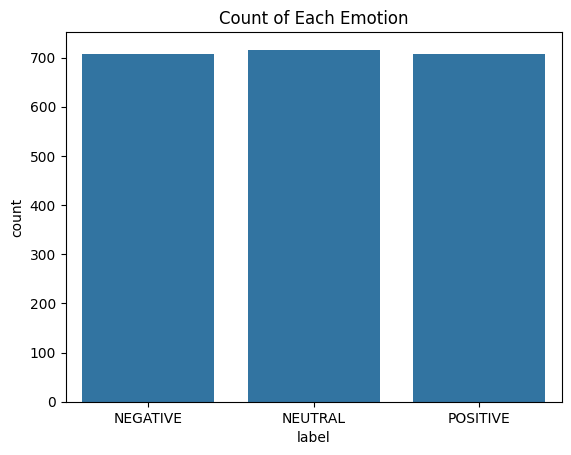

In [ ]:
sns.countplot(x="label", data=df)
plt.title("Count of Each Emotion")
plt.show()

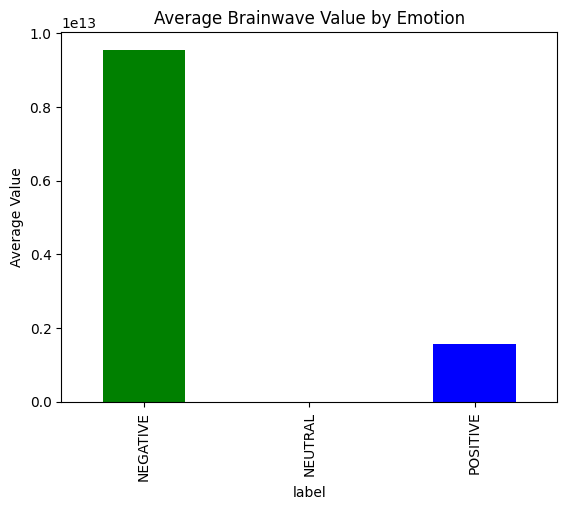

In [ ]:
# Average brainwave value for each emotion
avg = df.groupby('label').mean(numeric_only=True).mean(axis=1)
avg.plot(kind='bar', color=['green','red','blue'])
plt.title('Average Brainwave Value by Emotion')
plt.ylabel('Average Value')
plt.show()

Graphs show the count of each emotion and the average brainwave value. It is clear that emotions have different patterns.

# mean_0_a    0
mean_1_a      0
mean_2_a      0
mean_3_a      0
mean_4_a      0
             ..
fft_746_b     0
fft_747_b     0
fft_748_b     0
fft_749_b     0
label         0
Length: 2549, dtype: int64


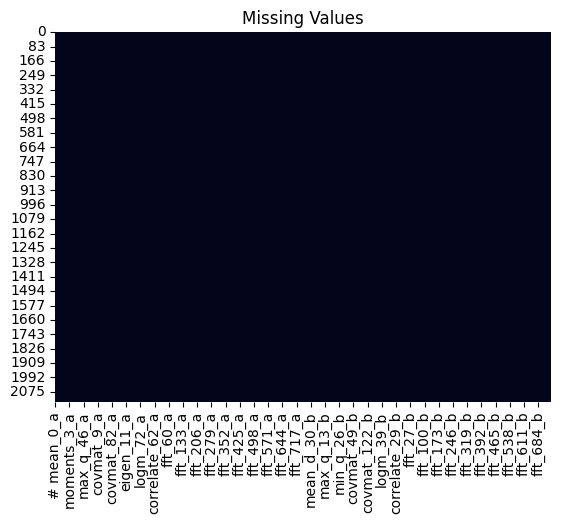

In [ ]:
# Missing values count
print(df.isnull().sum())

# Graph
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values")
plt.show()

"Missing values 0 hain, is liye hum ne kuch drop ya fill nahi kiya, kyun ke data pehle se hi clean hai."

In [ ]:
# Kitne duplicate hain
print("Duplicate rows:", df.duplicated().sum())

# Remove karna
df = df.drop_duplicates()
print("After removing:", df.shape)

Duplicate rows: 0
After removing: (2132, 2549)


In [ ]:
print(df.columns.tolist())

['# mean_0_a', 'mean_1_a', 'mean_2_a', 'mean_3_a', 'mean_4_a', 'mean_d_0_a', 'mean_d_1_a', 'mean_d_2_a', 'mean_d_3_a', 'mean_d_4_a', 'mean_d_0_a2', 'mean_d_1_a2', 'mean_d_2_a2', 'mean_d_3_a2', 'mean_d_4_a2', 'mean_d_5_a', 'mean_d_6_a', 'mean_d_7_a', 'mean_d_8_a', 'mean_d_9_a', 'mean_d_10_a', 'mean_d_11_a', 'mean_d_12_a', 'mean_d_13_a', 'mean_d_14_a', 'mean_d_15_a', 'mean_d_16_a', 'mean_d_17_a', 'mean_d_18_a', 'mean_d_19_a', 'mean_d_20_a', 'mean_d_21_a', 'mean_d_22_a', 'mean_d_23_a', 'mean_d_24_a', 'mean_d_25_a', 'mean_d_26_a', 'mean_d_27_a', 'mean_d_28_a', 'mean_d_29_a', 'mean_d_30_a', 'mean_d_31_a', 'mean_d_32_a', 'mean_d_33_a', 'mean_d_34_a', 'mean_d_35_a', 'mean_d_36_a', 'mean_d_37_a', 'mean_d_38_a', 'mean_d_39_a', 'mean_d_40_a', 'mean_d_41_a', 'mean_d_42_a', 'mean_d_43_a', 'mean_d_44_a', 'mean_d_45_a', 'mean_d_46_a', 'mean_d_47_a', 'mean_d_48_a', 'mean_d_49_a', 'stddev_0_a', 'stddev_1_a', 'stddev_2_a', 'stddev_3_a', 'stddev_4_a', 'stddev_d_0_a', 'stddev_d_1_a', 'stddev_d_2_a', 'std

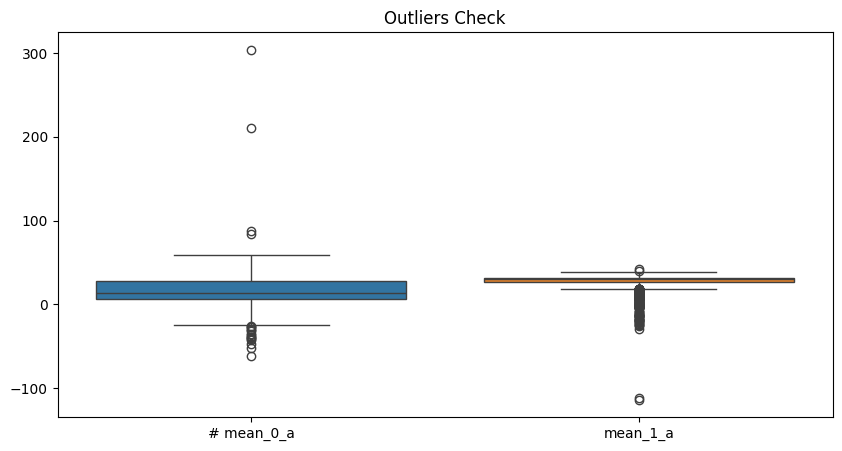

# mean_0_a Outliers: 20
mean_1_a Outliers: 202


In [ ]:
# Box plot
plt.figure(figsize=(10,5))
sns.boxplot(data=df[['# mean_0_a','mean_1_a']])
plt.title("Outliers Check")
plt.show()

# IQR rule
for col in ['# mean_0_a','mean_1_a']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR
    print(col, "Outliers:", ((df[col] < lower) | (df[col] > upper)).sum())

"Only a few outliers were found using the IQR rule, so no data was removed."

## Histograme

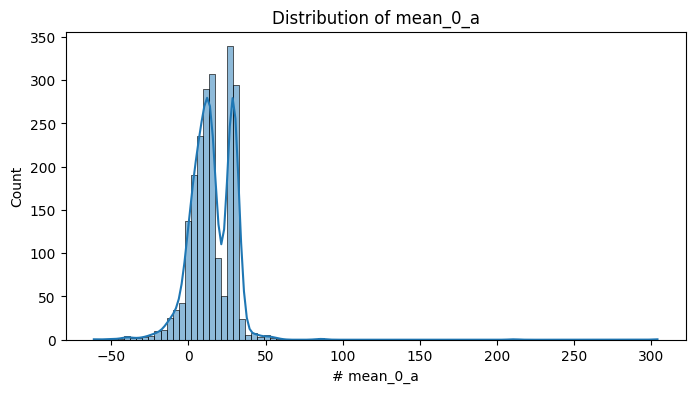

In [ ]:
plt.figure(figsize=(8,4))
sns.histplot(df["# mean_0_a"], kde=True)
plt.title("Distribution of mean_0_a")
plt.show()

"The distribution is mostly normal with some variation."

## Count plot

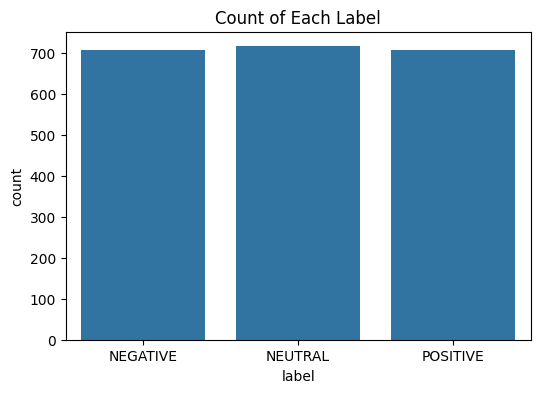

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x="label", data=df)
plt.title("Count of Each Label")
plt.show()

"The dataset contains different categories of labels."

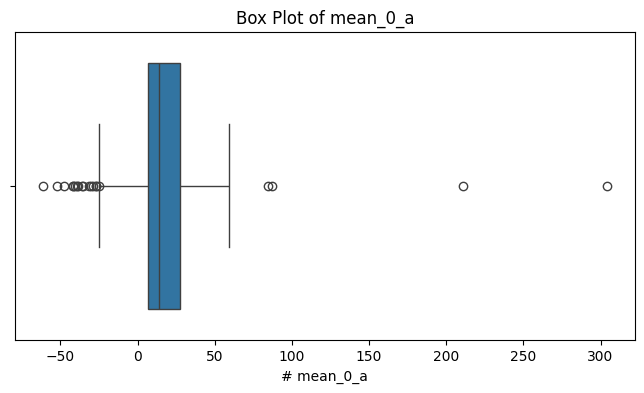

In [ ]:
# 1. Box Plot - Numeric
plt.figure(figsize=(8,4))
sns.boxplot(x=df['# mean_0_a'])
plt.title("Box Plot of mean_0_a")
plt.show()

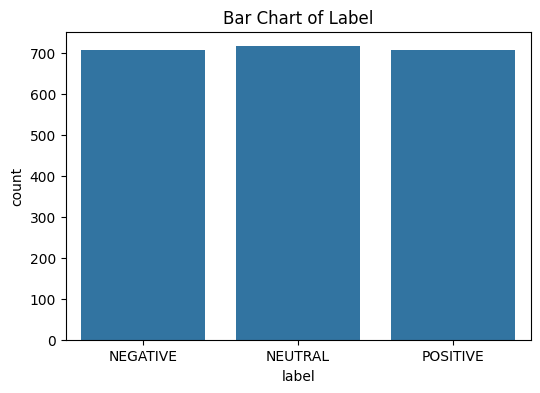

In [ ]:
 # Bar Chart - Category
plt.figure(figsize=(6,4))
sns.countplot(x='label', data=df)
plt.title("Bar Chart of Label")
plt.show()

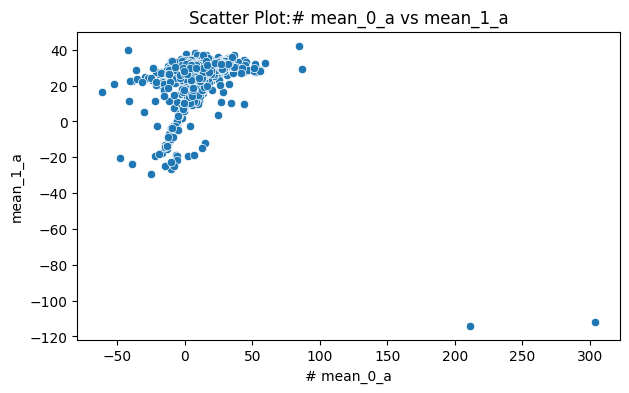

In [ ]:
# 1. Scatter Plot
plt.figure(figsize=(7,4))
sns.scatterplot(x='# mean_0_a', y='mean_1_a', data=df)
plt.title("Scatter Plot:# mean_0_a vs mean_1_a")
plt.show()

There is a weak relationship between mean_0_a and mean_1_a.

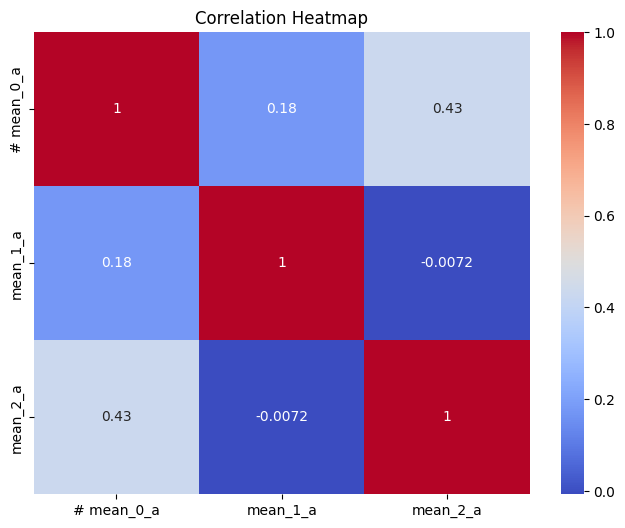

In [ ]:
# 2. Correlation Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df[['# mean_0_a','mean_1_a','mean_2_a']].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

The correlation between numeric columns is low to moderate

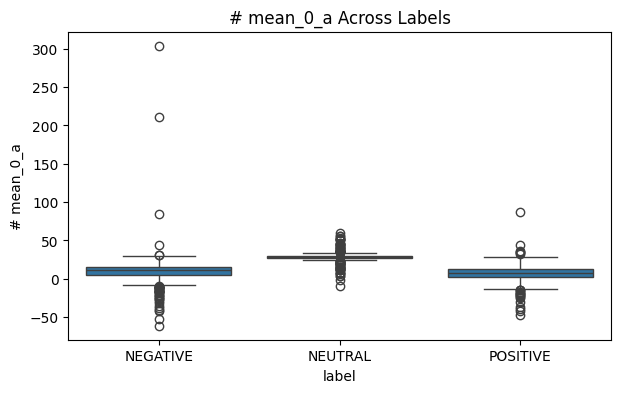

In [ ]:
# 3. Box Plot - Numeric vs Category
plt.figure(figsize=(7,4))
sns.boxplot(x='label', y='# mean_0_a', data=df)
plt.title("# mean_0_a Across Labels")
plt.show()

 "mean_0_a values vary across different labels.

label
NEUTRAL     716
NEGATIVE    708
POSITIVE    708
Name: count, dtype: int64


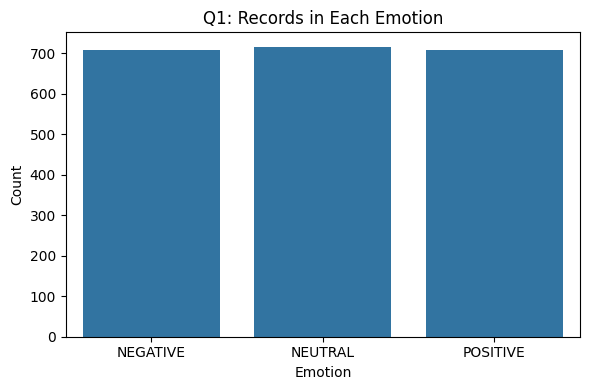

Answer: The category counts are {'NEUTRAL': 716, 'NEGATIVE': 708, 'POSITIVE': 708}


In [ ]:
# Q1. How many records belong to each emotion?
counts = df["label"].value_counts()
print(counts)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="label", order=["NEGATIVE", "NEUTRAL", "POSITIVE"])
plt.title("Q1: Records in Each Emotion")
plt.xlabel("Emotion")
plt.ylabel("Count")
plt.tight_layout()
plt.show()
print("Answer: The category counts are", counts.to_dict())

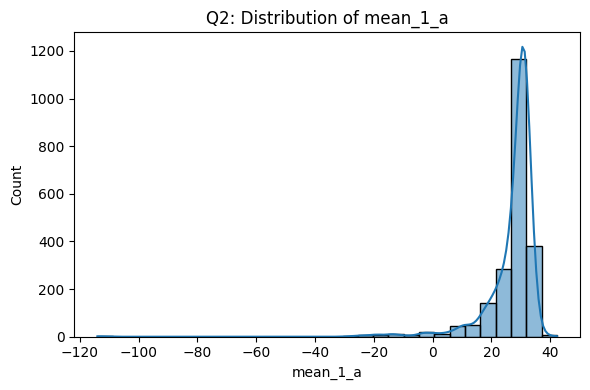

Answer: Mean = 27.01 and median = 30.0


In [ ]:
# Q2. What is the distribution of mean_1_a?
plt.figure(figsize=(6, 4))
sns.histplot(df["mean_1_a"], bins=30, kde=True)
plt.title("Q2: Distribution of mean_1_a")
plt.xlabel("mean_1_a")
plt.ylabel("Count")
plt.tight_layout()
plt.show()
print("Answer: Mean =", round(df["mean_1_a"].mean(), 2), "and median =", round(df["mean_1_a"].median(), 2))

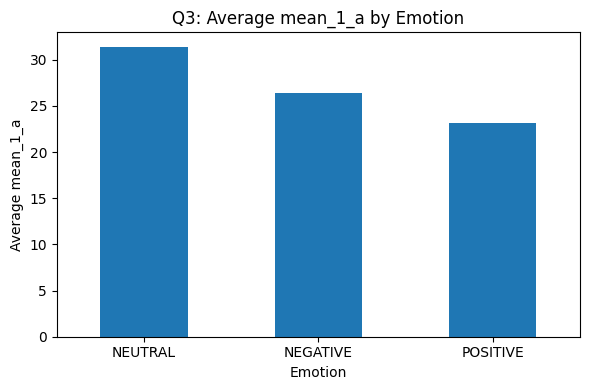

Answer: The highest average is for NEUTRAL with 31.41


In [ ]:
# Q3. Which emotion has the highest average mean_1_a?
avg_mean = df.groupby("label")["mean_1_a"].mean().sort_values(ascending=False)
plt.figure(figsize=(6, 4))
avg_mean.plot(kind="bar")
plt.title("Q3: Average mean_1_a by Emotion")
plt.xlabel("Emotion")
plt.ylabel("Average mean_1_a")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("Answer: The highest average is for", avg_mean.idxmax(), "with", round(avg_mean.max(), 2))

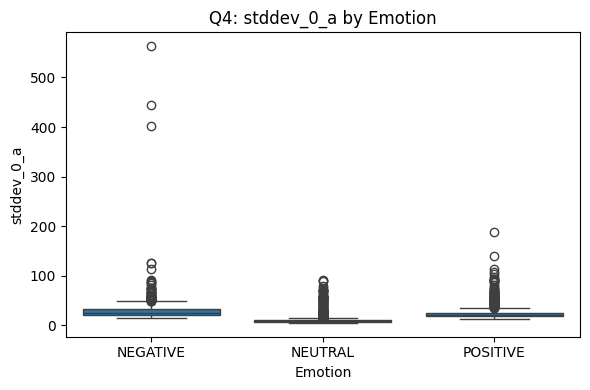

label
NEGATIVE    25.30
NEUTRAL      8.48
POSITIVE    21.30
Name: stddev_0_a, dtype: float64
Answer: The box plot compares the spread and median of stddev_0_a for each emotion.


In [ ]:
# Q4. Does stddev_0_a vary across the three emotions?
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="label", y="stddev_0_a", order=["NEGATIVE", "NEUTRAL", "POSITIVE"])
plt.title("Q4: stddev_0_a by Emotion")
plt.xlabel("Emotion")
plt.ylabel("stddev_0_a")
plt.tight_layout()
plt.show()
print(df.groupby("label")["stddev_0_a"].median().round(2))
print("Answer: The box plot compares the spread and median of stddev_0_a for each emotion.")

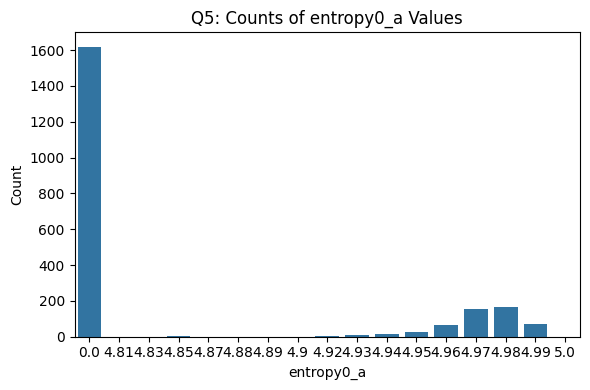

Answer: Values and their counts: {0.0: 1618, 4.81: 1, 4.83: 1, 4.85: 2, 4.87: 1, 4.88: 1, 4.89: 1, 4.9: 1, 4.92: 3, 4.93: 8, 4.94: 15, 4.95: 26, 4.96: 65, 4.97: 152, 4.98: 165, 4.99: 71, 5.0: 1}


In [ ]:
# Q5. How are entropy0_a values distributed?
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="entropy0_a")
plt.title("Q5: Counts of entropy0_a Values")
plt.xlabel("entropy0_a")
plt.ylabel("Count")
plt.tight_layout()
plt.show()
print("Answer: Values and their counts:", df["entropy0_a"].value_counts().sort_index().to_dict())

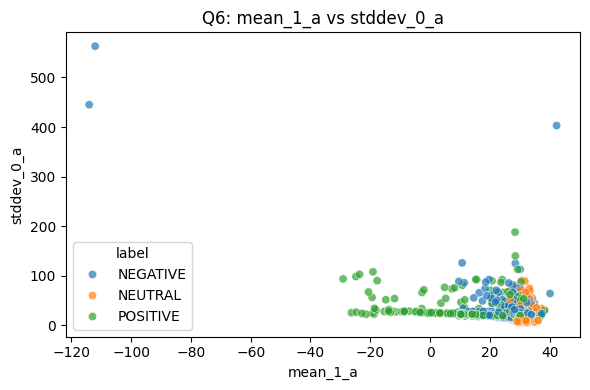

Answer: Correlation = -0.45 (negative means the two features tend to move in opposite directions).


In [ ]:
# Q6. Is there a relationship between mean_1_a and stddev_0_a?
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x="mean_1_a", y="stddev_0_a", hue="label", alpha=0.7)
plt.title("Q6: mean_1_a vs stddev_0_a")
plt.xlabel("mean_1_a")
plt.ylabel("stddev_0_a")
plt.tight_layout()
plt.show()
r = df["mean_1_a"].corr(df["stddev_0_a"])
print("Answer: Correlation =", round(r, 2), "(negative means the two features tend to move in opposite directions).")

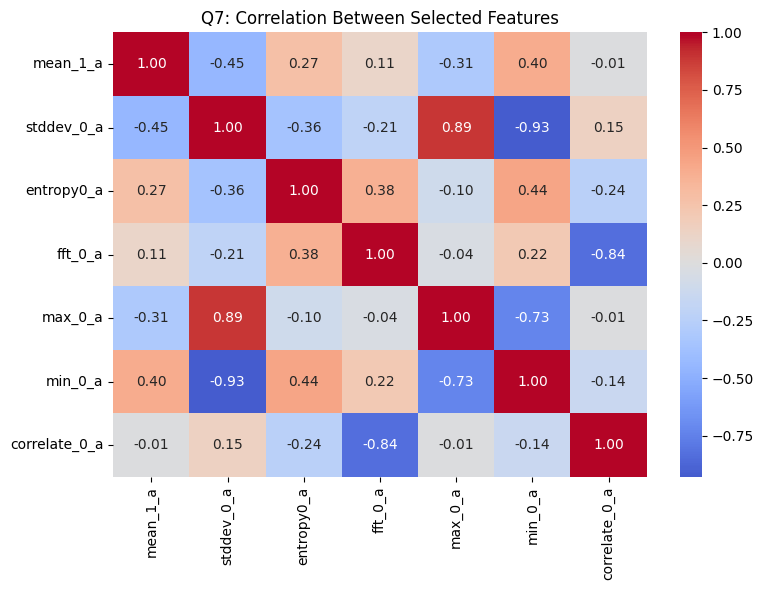

Answer: The heatmap shows positive and negative relationships. Stronger values closer to +1 or -1 indicate stronger linear relationships.


In [ ]:
# Q7. Which selected EEG features are correlated?
selected = ["mean_1_a", "stddev_0_a", "entropy0_a", "fft_0_a", "max_0_a", "min_0_a", "correlate_0_a"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[selected].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Q7: Correlation Between Selected Features")
plt.tight_layout()
plt.show()
corr = df[selected].corr()
print("Answer: The heatmap shows positive and negative relationships. Stronger values closer to +1 or -1 indicate stronger linear relationships.")

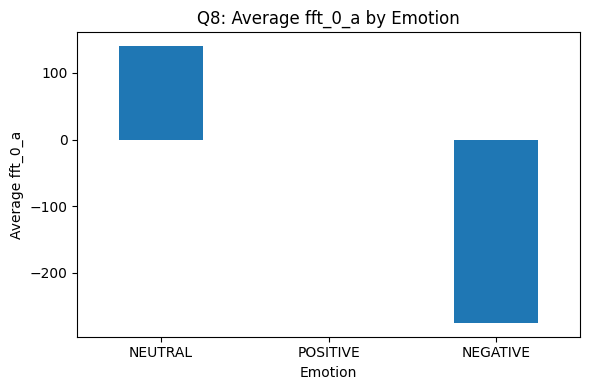

Answer: The highest average is for NEUTRAL with 140.1


In [ ]:
# Q8. Which emotion has the highest average fft_0_a?
avg_fft = df.groupby("label")["fft_0_a"].mean().sort_values(ascending=False)
plt.figure(figsize=(6, 4))
avg_fft.plot(kind="bar")
plt.title("Q8: Average fft_0_a by Emotion")
plt.xlabel("Emotion")
plt.ylabel("Average fft_0_a")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("Answer: The highest average is for", avg_fft.idxmax(), "with", round(avg_fft.max(), 2))

#7.Step 7 – Conclusion
After running all cells, write your final conclusion using the actual graphs and printed values. Use this format:
1. Finding 1: State which emotion group has the most records.
2. Finding 2: State which emotion has the highest average mean_1_a.
3. Finding 3: Describe one important relationship or difference shown by the scatter plot, box plot or heatmap